In [184]:
"""
===============================================================================
District Generator
===============================================================================

Creates a synthetic urban district.

Outputs
-------
district.street_graph
district.blocks
district.buildings
"""

import random
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches


class DistrictGenerator:

    # ---------------------------------------------------------------------
    # Constructor
    # ---------------------------------------------------------------------

    def __init__(self,
                 width=1200,
                 height=800,
                 rows=5,
                 cols=7,
                 street_width=15,
                 n_substations=100,
                 block_variation=0.12,
                 perturbation=5,
                 seed=42):

        self.width = width
        self.height = height

        self.rows = rows
        self.cols = cols

        self.street_width = street_width
        self.block_variation = block_variation

        self.n_substations = n_substations

        self.perturbation = perturbation

        self.seed = seed

        random.seed(seed)

        self.blocks = []
        self.buildings = []

        self.street_nodes = {}
        self.street_edges = []

        self.street_graph = nx.Graph()

    # ---------------------------------------------------------------------
    # Utilities
    # ---------------------------------------------------------------------

    def random_partition(self, total, n):

        mean = total / n

        values = [
            mean * (1 + random.uniform(-self.block_variation,
                                       self.block_variation))
            for _ in range(n)
        ]

        scale = total / sum(values)

        values = [v * scale for v in values]

        values[-1] = total - sum(values[:-1])

        return values

    def nearest_node(self, x, y):

        return min(
            self.street_nodes,
            key=lambda k:
            abs(self.street_nodes[k][0] - x)
            + abs(self.street_nodes[k][1] - y)
        )

    # ---------------------------------------------------------------------
    # Street grid
    # ---------------------------------------------------------------------

    def build_street_grid(self):

        usable_width = self.width - (self.cols + 1) * self.street_width
        usable_height = self.height - (self.rows + 1) * self.street_width

        self.block_widths = self.random_partition(
            usable_width,
            self.cols)

        self.block_heights = self.random_partition(
            usable_height,
            self.rows)

        self.x = [0]

        for bw in self.block_widths:

            self.x.append(self.x[-1] + self.street_width)
            self.x.append(self.x[-1] + bw)

        self.y = [0]

        for bh in self.block_heights:

            self.y.append(self.y[-1] + self.street_width)
            self.y.append(self.y[-1] + bh)

        # street nodes

        for i, xx in enumerate(self.x):
            for j, yy in enumerate(self.y):

                self.street_nodes[(i, j)] = (xx, yy)

        # edges

        for i in range(len(self.x)-1):
            for j in range(len(self.y)):

                self.street_edges.append(((i, j), (i+1, j)))

        for i in range(len(self.x)):
            for j in range(len(self.y)-1):

                self.street_edges.append(((i, j), (i, j+1)))

        # graph

        for node, pos in self.street_nodes.items():

            self.street_graph.add_node(node, pos=pos)

        for n1, n2 in self.street_edges:

            x1, y1 = self.street_nodes[n1]
            x2, y2 = self.street_nodes[n2]

            L = abs(x2-x1) + abs(y2-y1)

            self.street_graph.add_edge(
                n1,
                n2,
                length=L)

    # ---------------------------------------------------------------------
    # Blocks
    # ---------------------------------------------------------------------

    def build_blocks(self):

        block_id = 0

        for c in range(self.cols):

            for r in range(self.rows):

                x0 = self.x[2*c+1]
                y0 = self.y[2*r+1]

                self.blocks.append({

                    "id": block_id,

                    "x": x0,
                    "y": y0,

                    "width": self.block_widths[c],
                    "height": self.block_heights[r],

                    "area":
                    self.block_widths[c] *
                    self.block_heights[r]

                })

                block_id += 1

    # ---------------------------------------------------------------------
    # Buildings
    # ---------------------------------------------------------------------

    def build_buildings(self):

        n_blocks = len(self.blocks)
        allocation = [1] * n_blocks
        remaining = self.n_substations - n_blocks

        while remaining > 0:

            i = random.randint(0, n_blocks-1)
            allocation[i] += 1
            remaining -= 1

        building_id = 0

        sides = ["N", "S", "E", "W"]

        for block, n in zip(self.blocks, allocation):

            x0 = block["x"]
            y0 = block["y"]

            bw = block["width"]
            bh = block["height"]

            for k in range(n):

                side = random.choice(sides)

                p = random.uniform(0.15, 0.85)

                if side == "N":

                    bx = x0 + p*bw
                    by = y0 + bh - self.perturbation

                elif side == "S":

                    bx = x0 + p*bw
                    by = y0 + self.perturbation

                elif side == "E":

                    bx = x0 + bw - self.perturbation
                    by = y0 + p*bh

                else:

                    bx = x0 + self.perturbation
                    by = y0 + p*bh

                bx += random.uniform(-self.perturbation,
                                     self.perturbation)

                by += random.uniform(-self.perturbation,
                                     self.perturbation)

                node = self.nearest_node(bx, by)

                self.buildings.append({

                    "id": building_id,

                    "x": bx,
                    "y": by,

                    "block": block["id"],

                    "street_node": node

                })

                building_id += 1

    # ---------------------------------------------------------------------
    # Generate
    # ---------------------------------------------------------------------

    def generate(self):

        self.build_street_grid()
        self.build_blocks()
        self.build_buildings()

        return self

    # ---------------------------------------------------------------------
    # Plot
    # ---------------------------------------------------------------------

    def plot(self):

        fig, ax = plt.subplots(figsize=(12,8))

        for block in self.blocks:

            ax.add_patch(

                patches.Rectangle(

                    (block["x"], block["y"]),

                    block["width"],
                    block["height"],

                    facecolor="#efefef",
                    edgecolor="gray",
                    linewidth=0.5

                )

            )

        for n1, n2 in self.street_edges:

            x1, y1 = self.street_nodes[n1]
            x2, y2 = self.street_nodes[n2]

            ax.plot([x1, x2],
                    [y1, y2],
                    color="lightgray",
                    lw=1)

        for b in self.buildings:

            ax.scatter(
                b["x"],
                b["y"],
                color="blue",
                s=20,
                zorder=10
    )
        ax.set_xlim(-10, self.width+10)
        ax.set_ylim(-10, self.height+10)

        ax.set_aspect("equal")

        ax.set_title(
            f"Synthetic District ({len(self.buildings)} substations)")

        plt.tight_layout()
        plt.show()

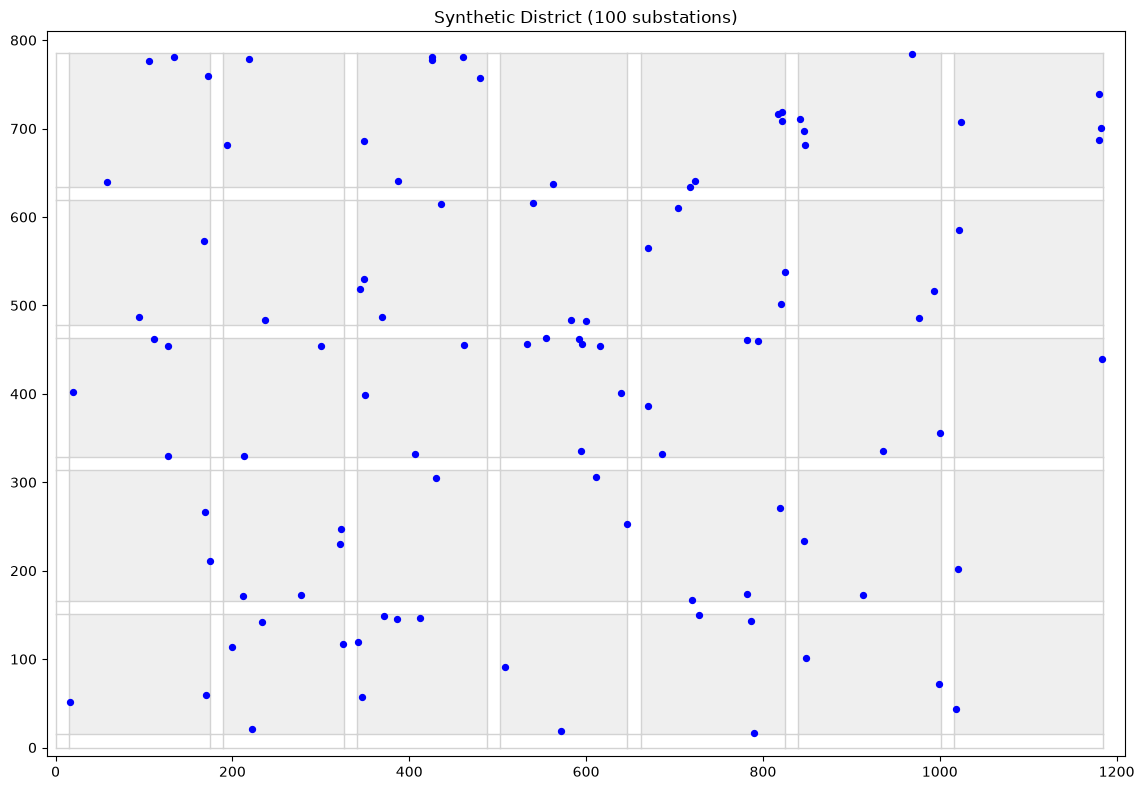

In [183]:
district = DistrictGenerator(
    width=1200,
    height=800,
    rows=5,
    cols=7,
    n_substations=100,
    seed=42
)

district.generate()

district.plot()